<a href="https://colab.research.google.com/github/Jess-chege/Data-Science-projects/blob/main/DTRF.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Assignment 3: Decision Tree vs. Random Forest Comparison
Objective: Compare Decision Tree and Random Forest classifiers on the same dataset to understand the benefits of ensemble methods.

Dataset: Assignment-Dataset/assignment3_classifier_comparison.csv

Context: A healthcare provider wants to predict diabetes risk based on patient health indicators. They want to understand which classifier provides better predictions and why.

Instructions:
Import necessary libraries
Load and preprocess the dataset
Perform comprehensive EDA including:
Feature distributions
Class distribution (Diabetes_Risk: 0 = Low Risk, 1 = High Risk)
Feature correlations
Analysis by physical activity level
Separate features (Age, BMI, Blood_Pressure, Glucose_Level, Insulin_Level, Family_History, Physical_Activity) and target (Diabetes_Risk)
Handle categorical feature (Physical_Activity) - encode appropriately (Low=0, Medium=1, High=2)
Split the data into training (80%) and test (20%) sets with random_state=42
Implement and evaluate:
Decision Tree (criterion='entropy', random_state=0)
Decision Tree (criterion='entropy', max_depth=5, random_state=0)
Random Forest (n_estimators=10, criterion='entropy', random_state=0)
Random Forest (n_estimators=50, criterion='entropy', random_state=0)
Compare all classifiers using:
Accuracy
Confusion matrices
Classification reports (precision, recall, f1-score)
Determine the best classifier for diabetes risk prediction


In [ ]:
#importing all the needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
#importing the dataset
dataset = pd.read_csv('/content/drive/MyDrive/assignment3_classifier_comparison (1).csv')
dataset.head()

,Patient_ID,Age,BMI,Blood_Pressure,Glucose_Level,Insulin_Level,Family_History,Physical_Activity,Diabetes_Risk
0,1,45,28.5,135,125,85,1,Low,1
1,2,32,24.2,118,92,45,0,High,0
2,3,58,31.8,148,165,142,1,Low,1
3,4,41,26.5,122,105,62,0,Medium,0
4,5,67,33.2,155,178,168,1,Low,1


In [ ]:
#performing the thorough EDA
#checking the data info
dataset.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Patient_ID         350 non-null    int64  
 1   Age                350 non-null    int64  
 2   BMI                350 non-null    float64
 3   Blood_Pressure     350 non-null    int64  
 4   Glucose_Level      350 non-null    int64  
 5   Insulin_Level      350 non-null    int64  
 6   Family_History     350 non-null    int64  
 7   Physical_Activity  350 non-null    object 
 8   Diabetes_Risk      350 non-null    int64  
dtypes: float64(1), int64(7), object(1)
memory usage: 24.7+ KB


In [ ]:
#checking the dataset shape
dataset.shape


(350, 9)

In [ ]:
#calculating statistical descriptions
dataset.describe()

,Patient_ID,Age,BMI,Blood_Pressure,Glucose_Level,Insulin_Level,Family_History,Diabetes_Risk
count,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000,350.000000
mean,175.500000,47.208571,28.319429,134.340000,129.920000,96.620000,0.540000,0.565714
std,101.180532,11.831648,3.583466,16.067242,32.499229,46.469279,0.499111,0.496372
min,1.000000,27.000000,22.200000,108.000000,82.000000,32.000000,0.000000,0.000000
25%,88.250000,37.000000,25.500000,119.000000,97.000000,50.000000,0.000000,0.000000
50%,175.500000,47.000000,28.200000,137.000000,130.000000,88.000000,1.000000,1.000000
75%,262.750000,58.000000,31.200000,148.000000,162.000000,145.000000,1.000000,1.000000
max,350.000000,67.000000,35.500000,162.000000,182.000000,175.000000,1.000000,1.000000


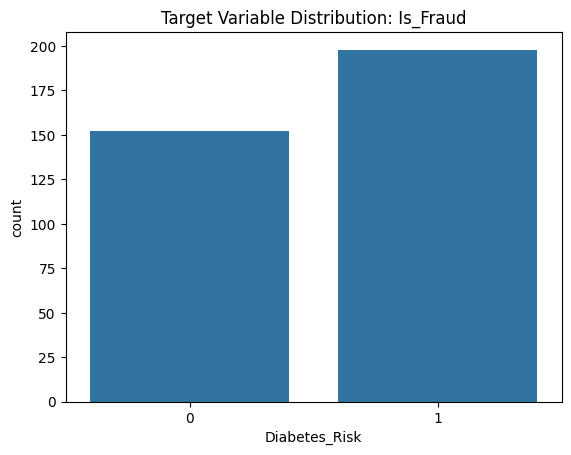

In [ ]:
#the visualizations to focus on features relationships
# Target variable distribution
sns.countplot(x='Diabetes_Risk', data=dataset)
plt.title("Target Variable Distribution: Is_Fraud")
plt.show()

In [ ]:
#identifying all categorical columns
cat_cols = dataset.select_dtypes(include=['object', 'category']).columns
print("Categorical columns:", cat_cols)

Categorical columns: Index(['Physical_Activity'], dtype='object')


In [ ]:
#encoding the categorical variables using the ordinal encoding

ordinal_mapping = {'Low': 0, 'Medium': 1, 'High': 2}
dataset['Physical_Activity'] = dataset['Physical_Activity'].map(ordinal_mapping)


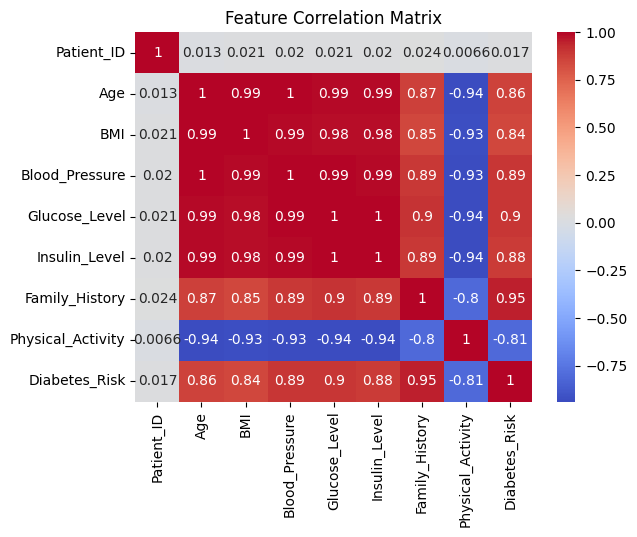

In [ ]:
#creating the Correlation matrix
corr = dataset.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title("Feature Correlation Matrix")
plt.show()

<Axes: xlabel='Diabetes_Risk', ylabel='count'>

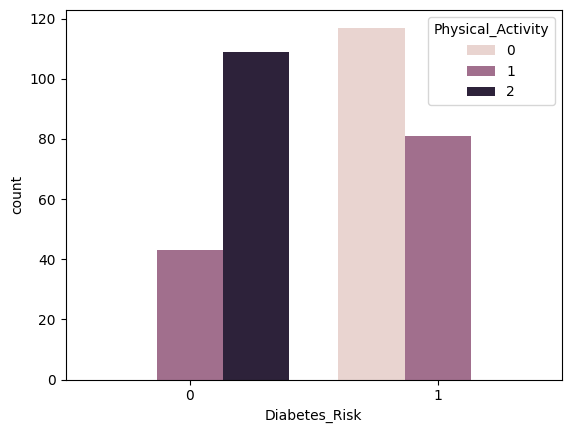

In [ ]:
#creating a countplot to visualize the diabetes risk and the physical activity
sns.countplot(x='Diabetes_Risk', hue='Physical_Activity', data=dataset)



<Axes: xlabel='Physical_Activity', ylabel='BMI'>

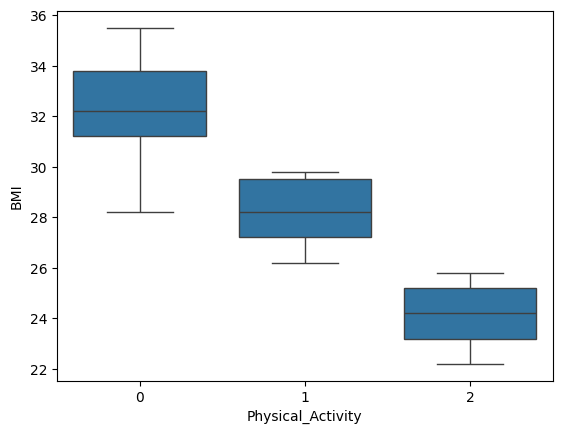

In [ ]:
#visualizing using the boxplot for the physical activity and the bmi
sns.boxplot(x='Physical_Activity', y='BMI', data=dataset)

In [ ]:
#dropping the patient id column as it has 0 impact
data = dataset.drop(['Patient_ID'], axis=1)
data.head()

,Age,BMI,Blood_Pressure,Glucose_Level,Insulin_Level,Family_History,Physical_Activity,Diabetes_Risk
0,45,28.5,135,125,85,1,0,1
1,32,24.2,118,92,45,0,2,0
2,58,31.8,148,165,142,1,0,1
3,41,26.5,122,105,62,0,1,0
4,67,33.2,155,178,168,1,0,1


In [ ]:
#separating the target variable and the dependent variables(x and y)
X = data.drop('Diabetes_Risk', axis=1)
Y = data['Diabetes_Risk']

In [ ]:
#splitting the dataset to train and test using 20% and 80%
from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size=0.2, random_state=42)

In [ ]:
#training the decision tree models
from sklearn.tree import DecisionTreeClassifier
dt1= DecisionTreeClassifier(criterion='entropy', random_state=0)
dt2 = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=0)

In [ ]:
#training the random forest models
from sklearn.ensemble import RandomForestClassifier
rf1 = RandomForestClassifier(n_estimators=10, criterion='entropy', random_state=0)
rf2 = RandomForestClassifier(n_estimators=50, criterion='entropy', random_state=0)


In [ ]:
#creating a function that handles the predictions from the 4 models
#importing the metrics
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
classifiers = {
    "Decision Tree (full)": dt1,
    "Decision Tree (max_depth=5)": dt2,
    "Random Forest (10 trees)": rf1,
    "Random Forest (50 trees)": rf2
}

results = {}

for name, cl in classifiers.items():
    cl.fit(X_train, Y_train)
    y_pred = cl.predict(X_test)

    acc = accuracy_score(Y_test, y_pred)
    cm = confusion_matrix(Y_test, y_pred)
    cr = classification_report(Y_test, y_pred, output_dict=True)

    results[name] = {
        "accuracy": acc,
        "confusion_matrix": cm,
        "classification_report": cr
    }


In [ ]:
for name, metrics in results.items():
    print(f" {name}")
    print("Accuracy:", metrics["accuracy"])
    print("Confusion Matrix:\n", metrics["confusion_matrix"])
    print("Classification Report:\n", classification_report(
        Y_test, classifiers[name].predict(X_test)
    ))
    print("\n")


 Decision Tree (full)
Accuracy: 1.0
Confusion Matrix:
 [[32  0]
 [ 0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00        38

    accuracy                           1.00        70
   macro avg       1.00      1.00      1.00        70
weighted avg       1.00      1.00      1.00        70



 Decision Tree (max_depth=5)
Accuracy: 1.0
Confusion Matrix:
 [[32  0]
 [ 0 38]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00        32
           1       1.00      1.00      1.00        38

    accuracy                           1.00        70
   macro avg       1.00      1.00      1.00        70
weighted avg       1.00      1.00      1.00        70



 Random Forest (10 trees)
Accuracy: 1.0
Confusion Matrix:
 [[32  0]
 [ 0 38]]
Classification Report:
               precision    recall  f1

In [ ]:
#creating summary table for easier analysis
rows = []

for name, metrics in results.items():
    cr = metrics["classification_report"]
    rows.append({
        "Classifier": name,
        "Accuracy": metrics["accuracy"],
        "Precision": cr["1"]["precision"],  # class 1 = High Risk
        "Recall": cr["1"]["recall"],
        "F1-Score": cr["1"]["f1-score"]
    })
summary = pd.DataFrame(rows)
summary


,Classifier,Accuracy,Precision,Recall,F1-Score
0,Decision Tree (full),1.0,1.0,1.0,1.0
1,Decision Tree (max_depth=5),1.0,1.0,1.0,1.0
2,Random Forest (10 trees),1.0,1.0,1.0,1.0
3,Random Forest (50 trees),1.0,1.0,1.0,1.0


### Observation
Perfect Performance Across Models:
All four classifiers achieved 100% across all metrics on the test set. The confusion matrices show zero false positives and zero false negatives. This means that every high-risk patient was correctly identified, and no low-risk patient was incorrectly flagged.

Effect of Model Complexity:
Increasing model complexity (e.g., deeper trees or more trees in Random Forest) did not improve performance, indicating that the dataset is highly separable. Even a simple shallow Decision Tree can perfectly classify the data.

Critical Metric - Recall:
Recall for high-risk patients is 1.0 across all models. In diabetes prediction, missing high-risk patients could have serious consequences, so this metric is the most important. This result is excellent because it ensures all high-risk patients are identified.

Precision and F1-Score:
Precision is also 1.0, which means the models don't flag low-risk patients as high-risk unnecessarily. F1-score, which balances precision and recall, is likewise perfect.

Dataset Insights:
The perfect scores suggest that the dataset is either relatively small, clean, and/or contains highly predictive features. Features like physical activity, BMI, age, or other risk factors likely provide strong signals for classification.

Why Random Forest Might Outperform Single Decision Tree

Ensemble Effect:

Random Forest combines predictions from multiple trees - reduces variance and overfitting.

Single Decision Tree can overfit easily on small datasets.

Robustness:

Random Forest averages results - more stable predictions on unseen data.

Single tree decisions can change drastically if small changes occur in the input.

Handling Noise:

Random Forest is less sensitive to noisy features or outliers.

Decision Tree may split on noisy features - poor generalization.

Random Forest trades a bit more computation for better generalization and stability, which is critical in healthcare where wrong predictions are costly.

Recommendations for Healthcare Deployment

Using Random Forest (50 trees) or Decision Tree (max_depth=5) for simplicity.

Both models perfectly identify high-risk patients on current data.

Random Forest is preferred if data grows or becomes more complex.

Prioritizing Recall for High-Risk Patients:

Missing high-risk patients can have serious consequences - model recall is critical.

Validating on Larger or Unseen Data:

Perfect scores may indicate small dataset or high separability.

Real-world deployment needs robust cross-validation and external validation.

Monitor Model Drift:

Track feature distributions over time.

Update the model periodically to maintain accuracy.

Integrate into Clinical Workflow Carefully:

Use predictions as decision support, not final diagnosis.

Combine model output with physician assessment.